<a href="https://colab.research.google.com/github/bilgeerol/bim448-sentiment/blob/main/notebooks/05_degerlendirme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 – Değerlendirme
**Sahibi:** Zehra · **Amaç:** Yedi tahmin dosyasını ortak `src/evaluate.py` ile değerlendirmek; metrik, hata tablosu ve karışıklık matrislerini üretmek.
**Girdi:** `predictions/*.csv`, `data/processed/{en,tr}_test.csv` · **Çıktı:** `results/tables/`, `results/figures/`

In [1]:
# 0. KURULUM HÜCRESİ — her oturumda ilk bu çalıştırılır
from google.colab import userdata, drive
import os

drive.mount('/content/drive')

TOKEN = userdata.get('GITHUB_TOKEN')
REPO_OWNER = "bilgeerol"
REPO = "bim448-sentiment"
REPO_DIR = f"/content/{REPO}"

if not os.path.exists(REPO_DIR):
    !git clone https://{TOKEN}@github.com/{REPO_OWNER}/{REPO}.git {REPO_DIR}
%cd {REPO_DIR}
!git pull
!git config user.name "zehranurBurmaoglu"
!git config user.email "znburmaoglu@gmail.com"

# Kontrol: depo geldi mi, push iznim var mı?
!ls
!git push --dry-run

Mounted at /content/drive
Cloning into '/content/bim448-sentiment'...
remote: Enumerating objects: 159, done.
remote: Counting objects: 100% (159/159), done.
remote: Compressing objects: 100% (109/109), done.
remote: Total 159 (delta 91), reused 98 (delta 42), pack-reused 0 (from 0)
Receiving objects: 100% (159/159), 4.44 MiB | 11.80 MiB/s, done.
Resolving deltas: 100% (91/91), done.
/content/bim448-sentiment
Already up to date.
data  notebooks  predictions  README.md  report  requirements.txt  results  src
Everything up-to-date


## 1. Ortak değerlendirme kodu (src/evaluate.py)

In [2]:
%%writefile src/evaluate.py
"""
evaluate.py — BİM 448 Duygu Analizi projesinin ortak değerlendirme kodu (sahibi: Zehra).

Kullanım (depo kök klasöründen):
    from src.evaluate import evaluate
    evaluate("predictions/bert_tr.csv", "BERT (BERTurk)", "TR")

Ürettiği dosyalar:
    results/tables/{ad}_metrikler.csv    sınıf bazında kesinlik, duyarlılık, F1 + makro ortalama + doğruluk
    results/tables/{ad}_hatalar.csv      sınıf bazında yanlış sınıflandırma sayıları
    results/tables/{ad}_karisiklik.csv   karışıklık matrisi (satır: gerçek, sütun: tahmin)
    results/figures/cm_{ad}.png          karışıklık matrisi görseli
    results/tables/ozet_metrikler.csv    her çağrı bir satır ekler (aynı model + dil varsa üzerine yazar)
{ad} = model adından türetilen kısa ad + "_" + dil, örn. "vader_cevirili_tr".
"""
import os
import unicodedata

import matplotlib
matplotlib.use("Agg")                       # ekran gerektirmeden PNG üret
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support

ETIKETLER = ["negative", "neutral", "positive"]                 # kodda her zaman bu sıra
TR_AD = {"negative": "Negatif", "neutral": "Nötr", "positive": "Pozitif", "invalid": "Geçersiz"}
DIL_AD = {"EN": "İngilizce", "TR": "Türkçe"}
ZORUNLU_SUTUNLAR = ["id", "text", "true_label", "pred_label"]

# Rapordaki model adı → dosya adlarında kullanılacak kısa ad
KISA_AD = {
    "VADER": "vader",
    "VADER (doğrudan)": "vader_dogrudan",
    "VADER (çeviri sonrası)": "vader_cevirili",
    "BERT (RoBERTa)": "bert",
    "BERT (BERTurk)": "bert",
    "LLM (gpt-oss-120b)": "llm",
}


def _kisa_ad(model_adi):
    """Model adını dosya adına uygun hale getirir (küçük harf, Türkçe karakter yok, alt çizgi)."""
    if model_adi in KISA_AD:
        return KISA_AD[model_adi]
    ad = model_adi.lower().replace("ı", "i")
    ad = unicodedata.normalize("NFKD", ad).encode("ascii", "ignore").decode()
    ad = "".join(ch if ch.isalnum() else "_" for ch in ad)
    return "_".join(p for p in ad.split("_") if p)


def _giris_kontrolu(df, dil, beklenen_satir, test_dir):
    """Tahmin dosyasının ortak kurallara uyup uymadığını kontrol eder; ciddi bir sorun varsa durur."""
    eksik = [s for s in ZORUNLU_SUTUNLAR if s not in df.columns]
    if eksik:
        raise ValueError(f"Eksik zorunlu sütun(lar): {eksik}")
    if beklenen_satir is not None and len(df) != beklenen_satir:
        raise ValueError(f"Satır sayısı {len(df)}, beklenen {beklenen_satir}")
    if df["id"].duplicated().any():
        raise ValueError(f"Tekrarlanan id var: {df['id'][df['id'].duplicated()].tolist()[:5]}")
    gecersiz_gercek = ~df["true_label"].isin(ETIKETLER)
    if gecersiz_gercek.any():
        raise ValueError(f"true_label sütununda geçersiz değer var: {df.loc[gecersiz_gercek, 'true_label'].unique()[:5]}")

    if test_dir is not None:                    # id'ler ve gerçek etiketler test setiyle birebir aynı mı?
        test = pd.read_csv(os.path.join(test_dir, f"{dil.lower()}_test.csv"), encoding="utf-8")
        if set(df["id"]) != set(test["id"]):
            raise ValueError("id'ler test setindeki id'lerle aynı değil")
        eslesme = df.merge(test[["id", "label"]], on="id")
        if (eslesme["true_label"] != eslesme["label"]).any():
            raise ValueError("true_label değerleri test setindeki etiketlerle uyuşmuyor")


def evaluate(pred_path, model_adi, dil, beklenen_satir=3000, test_dir="data/processed",
             tablo_dir="results/tables", sekil_dir="results/figures"):
    """
    Bir tahmin dosyasını değerlendirir, tabloları ve karışıklık matrisini kaydeder.

    pred_path      : tahmin dosyası (id, text, true_label, pred_label sütunları zorunlu)
    model_adi      : raporda görünecek ad, örn. "BERT (BERTurk)"
    dil            : "EN" ya da "TR"
    beklenen_satir : satır sayısı kontrolü (elle doğrulama için değiştirilebilir; None = kontrol yok)
    test_dir       : id ve etiket kontrolü için test setlerinin klasörü (None = kontrol yok)
    """
    dil = dil.upper()
    ad = f"{_kisa_ad(model_adi)}_{dil.lower()}"
    df = pd.read_csv(pred_path, encoding="utf-8", keep_default_na=False)
    _giris_kontrolu(df, dil, beklenen_satir, test_dir)

    y_true = df["true_label"]
    # Üç etiketten biri olmayan tahminler (boş, yazım hatası vb.) "invalid" olarak sayılır ve doğru kabul edilmez
    y_pred = df["pred_label"].where(df["pred_label"].isin(ETIKETLER), "invalid")
    n_gecersiz = int((y_pred == "invalid").sum())

    # --- Metrikler ---
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, destek = precision_recall_fscore_support(y_true, y_pred, labels=ETIKETLER, zero_division=0)
    mp, mr, mf1, _ = precision_recall_fscore_support(y_true, y_pred, labels=ETIKETLER, average="macro", zero_division=0)
    metrikler = pd.DataFrame({
        "Sınıf": [TR_AD[e] for e in ETIKETLER] + ["Makro ortalama", "Doğruluk"],
        "Kesinlik": list(p) + [mp, None],
        "Duyarlılık": list(r) + [mr, None],
        "F1-skoru": list(f1) + [mf1, acc],              # sklearn raporundaki gibi doğruluk F1 sütununda
        "Örnek sayısı": list(destek) + [int(destek.sum()), len(df)],
    })

    # --- Karışıklık matrisi (satır: gerçek, sütun: tahmin) ---
    sutunlar = ETIKETLER + (["invalid"] if n_gecersiz else [])
    cm = confusion_matrix(y_true, y_pred, labels=sutunlar)[:len(ETIKETLER), :]
    cm_df = pd.DataFrame(cm, index=[TR_AD[e] for e in ETIKETLER], columns=[TR_AD[e] for e in sutunlar])

    # --- Hata tablosu ---
    satirlar = []
    for i, e in enumerate(ETIKETLER):
        dogru = int(cm[i, i])
        kirilim = ", ".join(f"→{TR_AD[s]}: {int(cm[i, j])}" for j, s in enumerate(sutunlar) if j != i and cm[i, j] > 0)
        satirlar.append({
            "Sınıf": TR_AD[e],
            "Örnek sayısı": int(cm[i, :].sum()),
            "Doğru": dogru,
            "Gerçek sınıfa göre hata": int(cm[i, :].sum()) - dogru,     # satır toplamı − köşegen
            "Tahmine göre hata": int(cm[:, i].sum()) - dogru,           # sütun toplamı − köşegen
            "Hata kırılımı": kirilim or "—",
        })
    hatalar = pd.DataFrame(satirlar)
    toplam_hata = int(len(df) - cm.trace())

    # --- Kayıt ---
    os.makedirs(tablo_dir, exist_ok=True)
    os.makedirs(sekil_dir, exist_ok=True)
    metrikler.to_csv(os.path.join(tablo_dir, f"{ad}_metrikler.csv"), index=False, encoding="utf-8")
    hatalar.to_csv(os.path.join(tablo_dir, f"{ad}_hatalar.csv"), index=False, encoding="utf-8")
    cm_df.to_csv(os.path.join(tablo_dir, f"{ad}_karisiklik.csv"), encoding="utf-8")

    fig, ax = plt.subplots(figsize=(5.2 if n_gecersiz else 4.6, 4))
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 11})
    ax.set_xlabel("Tahmin edilen sınıf")
    ax.set_ylabel("Gerçek sınıf")
    ax.tick_params(axis="y", rotation=0)
    ax.set_title(f"{model_adi} – {DIL_AD.get(dil, dil)}")
    fig.tight_layout()
    fig.savefig(os.path.join(sekil_dir, f"cm_{ad}.png"), dpi=300)
    plt.close(fig)

    # --- Özet tablo: aynı model + dil varsa üzerine yaz ---
    ozet_yol = os.path.join(tablo_dir, "ozet_metrikler.csv")
    yeni = pd.DataFrame([{"model": model_adi, "dil": dil, "accuracy": acc, "macro_precision": mp,
                          "macro_recall": mr, "macro_f1": mf1, "toplam_hata": toplam_hata}])
    if os.path.exists(ozet_yol):
        ozet = pd.read_csv(ozet_yol, encoding="utf-8")
        ozet = ozet[~((ozet["model"] == model_adi) & (ozet["dil"] == dil))]
        ozet = pd.concat([ozet, yeni], ignore_index=True)
    else:
        ozet = yeni
    ozet.to_csv(ozet_yol, index=False, encoding="utf-8")

    print(f"{model_adi} – {dil}: {len(df)} satır | geçersiz tahmin: {n_gecersiz} | "
          f"doğruluk {acc:.3f} | makro-F1 {mf1:.3f} | toplam hata {toplam_hata} → dosyalar: {ad}_*")
    return {"metrikler": metrikler, "hatalar": hatalar, "karisiklik": cm_df}

Writing src/evaluate.py


Sahte Model – TR: 9 satır | geçersiz tahmin: 1 | doğruluk 0.556 | makro-F1 0.578 | toplam hata 4 → dosyalar: sahte_model_tr_*


,Negatif,Nötr,Pozitif,Geçersiz
Negatif,2,1,0,0
Nötr,1,1,1,0
Pozitif,0,0,2,1


,Sınıf,Örnek sayısı,Doğru,Gerçek sınıfa göre hata,Tahmine göre hata,Hata kırılımı
0,Negatif,3,2,1,1,→Nötr: 1
1,Nötr,3,1,2,1,"→Negatif: 1, →Pozitif: 1"
2,Pozitif,3,2,1,1,→Geçersiz: 1


,Sınıf,Kesinlik,Duyarlılık,F1-skoru,Örnek sayısı
0,Negatif,0.667,0.667,0.667,3
1,Nötr,0.500,0.333,0.400,3
2,Pozitif,0.667,0.667,0.667,3
3,Makro ortalama,0.611,0.556,0.578,9
4,Doğruluk,NaN,NaN,0.556,9


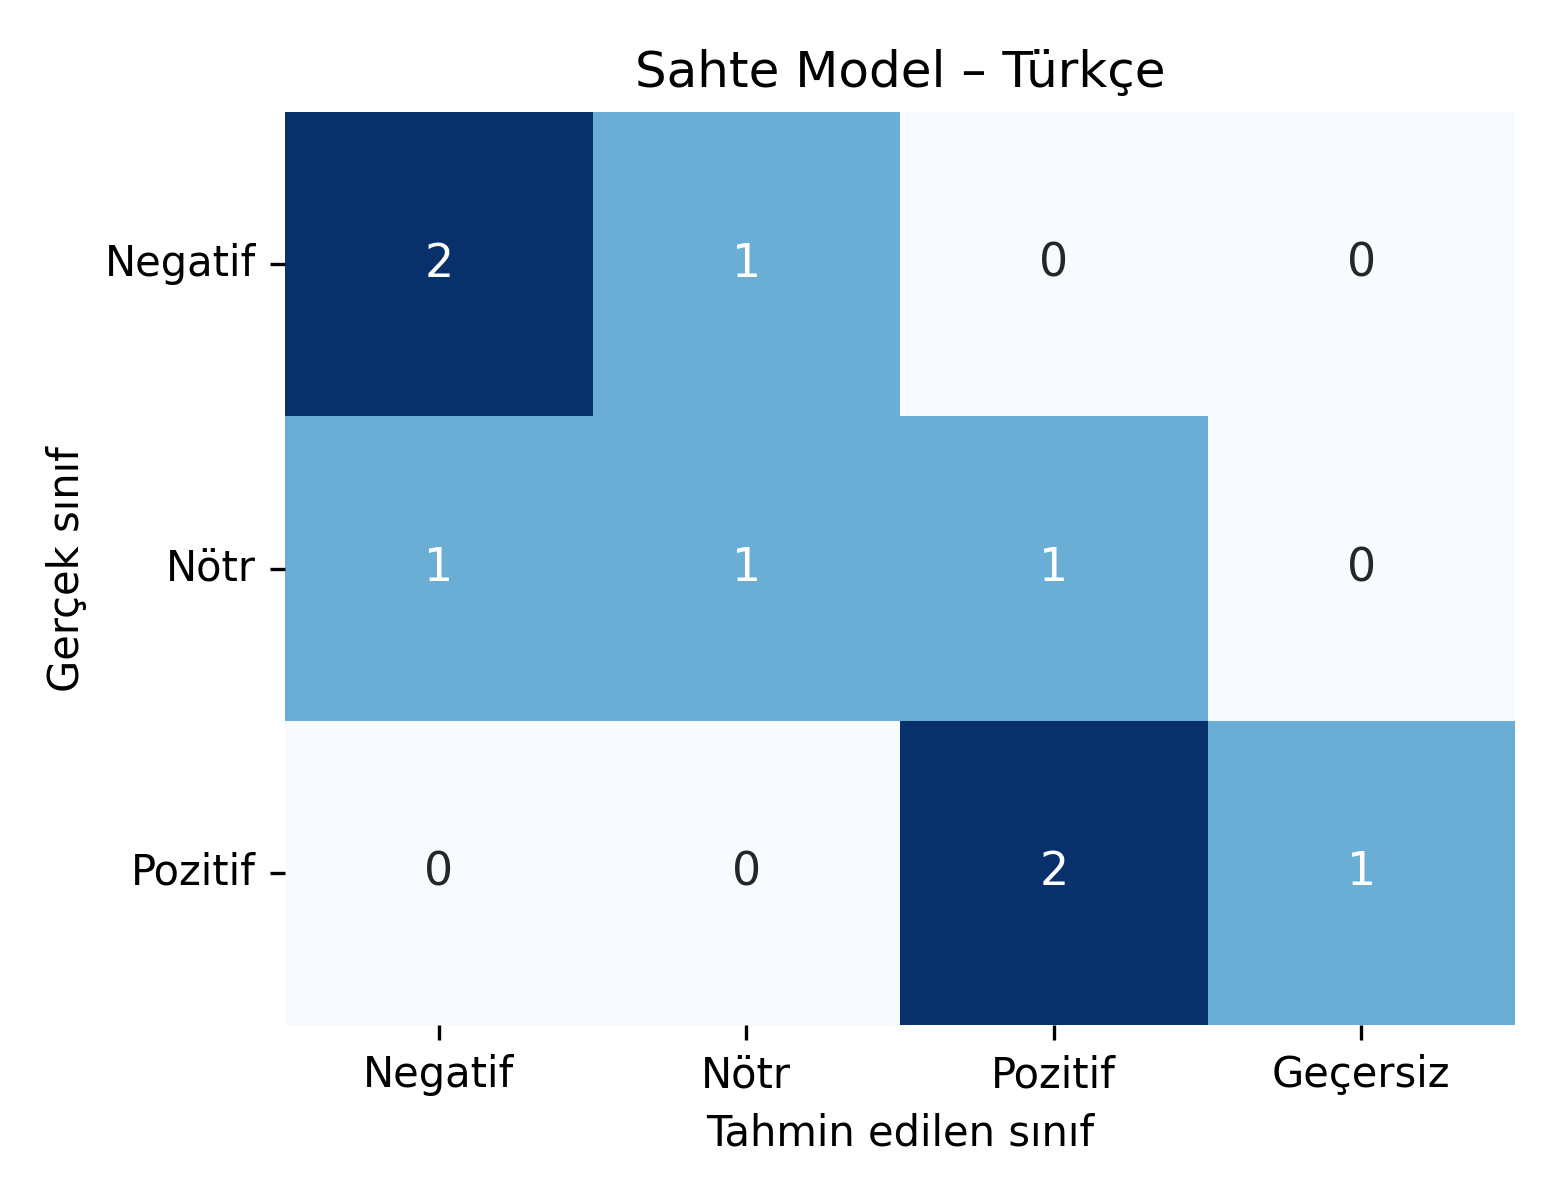

In [3]:
# 1.2 Elle doğrulama: 9 satırlık sahte tahmin dosyasıyla evaluate()'i test et (sonuçlar results/ klasörüne yazılmaz)
import importlib
import pandas as pd
from IPython.display import Image
import src.evaluate as ev
importlib.reload(ev)          # evaluate.py değişirse en güncel halini yükler

sahte = pd.DataFrame({
    "id": [f"x{i}" for i in range(1, 10)],
    "text": ["deneme"] * 9,
    "true_label": ["negative"] * 3 + ["neutral"] * 3 + ["positive"] * 3,
    "pred_label": ["negative", "negative", "neutral",
                   "neutral", "positive", "negative",
                   "positive", "positive", "pozitif"],      # sonuncusu bilerek yanlış yazıldı → geçersiz
})
os.makedirs("/content/deneme", exist_ok=True)
sahte.to_csv("/content/deneme/sahte_tahmin.csv", index=False, encoding="utf-8")

sonuc = ev.evaluate("/content/deneme/sahte_tahmin.csv", "Sahte Model", "TR",
                    beklenen_satir=9, test_dir=None,
                    tablo_dir="/content/deneme/tablolar", sekil_dir="/content/deneme/sekiller")
display(sonuc["karisiklik"])
display(sonuc["hatalar"])
display(sonuc["metrikler"].round(3))
display(Image("/content/deneme/sekiller/cm_sahte_model_tr.png", width=420))

In [4]:
# 1.3 Elle doğrulanan evaluate.py'yi GitHub'a gönder
!git status --short
!git add src/evaluate.py
!git commit -m "[Zehra] Ortak değerlendirme kodu src/evaluate.py eklendi (elle doğrulandı)"
!git pull --rebase
!git push

?? src/__pycache__/
?? src/evaluate.py
[main f7c8eb9] [Zehra] Ortak değerlendirme kodu src/evaluate.py eklendi (elle doğrulandı)
 1 file changed, 159 insertions(+)
 create mode 100644 src/evaluate.py
Current branch main is up to date.
Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 3.57 KiB | 3.57 MiB/s, done.
Total 4 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/bilgeerol/bim448-sentiment.git
   5677346..f7c8eb9  main -> main
